# Практическая работа №1. Введение в инструментарий анализа данных

**Дисциплина:** Технологии и инструментарий анализа больших данных
**Тема:** Основы использования Python как инструмента для первичного и разведочного анализа данных

| | |
|---|---|
| **Выполнил:** | Тагин Никита |
| **Группа:** | ИКБО-61-23 |
| **Дата выполнения:** | 26.10.2026 |

**Цель работы** — освоить базовый цикл анализа табличных данных: подготовить воспроизводимое окружение, загрузить данные,
проверить структуру и качество, выполнить предобработку, получить описательные статистики, сформировать аналитические срезы,
визуализировать закономерности и экспортировать подготовленный набор в CSV, JSON и Parquet.

Работа состоит из двух частей:
1. **Часть I** — учебные блоки на наборе `FiresRu.csv` (метеорологические условия пожаров в России, 2021–2022).
2. **Часть II** — самостоятельный анализ собственного датасета (`taxis.csv`, поездки такси Нью-Йорка, март 2019).

В конце приведены ответы на контрольные вопросы.

# Часть I. Учебные блоки на наборе FiresRu.csv

## 2. Рабочее окружение Python
### Практический блок 2.1. Создание окружения

Окружение создано в каталоге `.venv` рядом с блокнотом (macOS, zsh):

```bash
python3.13 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install pandas numpy matplotlib pyarrow jupyter
jupyter notebook
```

Блокнот также запущен онлайн в Google Colab (Chrome): там используется облачное окружение, а файлы `FiresRu.csv` и `taxis.csv` загружаются в хранилище сессии.

Ниже — проверка интерпретатора и того, что библиотеки импортируются без `ImportError`.

In [1]:
import sys
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Интерпретатор:", sys.executable)
print("Python:    ", sys.version.split()[0])
print("pandas:    ", pd.__version__)
print("NumPy:     ", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("PyArrow:   ", pyarrow.__version__)

DATA_PATH = Path("FiresRu.csv")
print("\nФайл данных найден:", DATA_PATH.exists())

Интерпретатор: /usr/bin/python3
Python:     3.13.16
pandas:     2.2.3
NumPy:      2.1.3
Matplotlib: 3.10.0
PyArrow:    23.0.1

Файл данных найден: True


**Вывод.** Интерпретатор работает (локально — из `.venv`, онлайн — в облачном окружении Google Colab), все библиотеки
(включая `pyarrow` для Parquet) импортируются, файл `FiresRu.csv` доступен. Версии зафиксированы в выводе выше — это делает работу воспроизводимой.

## 3. Минимальное введение в Python, NumPy и Pandas
### Практический блок 3.1. Векторное преобразование

Переводим скорость ветра из м/с в км/ч по формуле $v_{км/ч} = 3.6 \cdot v_{м/с}$ одной операцией над всем массивом.

In [2]:
wind_ms = np.array([1.14, 0.80, 0.97])
wind_kmh = wind_ms * 3.6
print(np.round(wind_kmh, 2))

[4.1  2.88 3.49]


**Вывод.** Умножение применено ко всем элементам сразу, без цикла. Тот же приём далее используется для столбца
DataFrame: `df["wind_speed_ms"] * 3.6`.

### Практический блок 3.2. Ключевые объекты Pandas

In [3]:
s = pd.Series([10, 20, 30], name="value")
frame = pd.DataFrame({
    "type": ["A", "B", "A"],
    "value": [10, 20, 30]
})
print(type(s).__name__)
print(type(frame).__name__)
print(frame.groupby("type")["value"].sum())

Series
DataFrame
type
A    40
B    20
Name: value, dtype: int64


**Вывод.** `Series` — один именованный столбец с индексом, `DataFrame` — набор согласованных `Series`.
`groupby()` реализует схему «разбить на группы → агрегировать»: для группы A сумма 10 + 30 = 40, для B — 20.

## 4. Форматы файлового хранения данных и загрузка CSV
### Практический блок 4.1. Загрузка FiresRu.csv

In [4]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(26681, 9)
['type_name', 'type_id', 'lon', 'lat', 'temperature_c', 'precipitation_mm', 'relative_humidity', 'wind_speed_ms', 'solar_radiation']


,type_name,type_id,lon,lat,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
0,Natural fire,4,131.5866,47.8662,-9.44,0.01,72.98,1.14,4.59
1,Natural fire,4,131.5885,47.8809,-9.44,0.01,72.98,1.14,4.59
2,Forest fire,3,131.9871,48.4973,-10.71,0.05,81.31,0.80,4.24
3,Natural fire,4,131.9031,43.6277,-7.77,0.00,68.41,0.97,4.66
4,Natural fire,4,131.5706,47.8581,-9.44,0.01,72.98,1.14,4.59


**Вывод.** Файл прочитан без явного указания `sep` и `encoding` (стандартный разделитель «,», UTF-8):
26 681 строка и 9 столбцов. Среди полей нет даты/времени — временной анализ на этом наборе некорректен.

## 5. Первичная диагностика данных
### Практический блок 5.1. Структура и память

In [5]:
buf = io.StringIO()
df.info(buf=buf, memory_usage="deep")
print(buf.getvalue())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26681 entries, 0 to 26680
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   type_name          26681 non-null  object 
 1   type_id            26681 non-null  int64  
 2   lon                26681 non-null  float64
 3   lat                26681 non-null  float64
 4   temperature_c      26681 non-null  float64
 5   precipitation_mm   26681 non-null  float64
 6   relative_humidity  26681 non-null  float64
 7   wind_speed_ms      26681 non-null  float64
 8   solar_radiation    26681 non-null  float64
dtypes: float64(7), int64(1), object(1)
memory usage: 3.2 MB



**Вывод.** Пропусков нет (во всех столбцах 26 681 non-null). Семь признаков — `float64`, `type_id` — `int64`,
`type_name` — строковый (`object` в pandas 2.x, как в методичке; в pandas 3 — отдельный тип `str`).
Столбец `type_name` содержит всего 5 повторяющихся значений — кандидат на тип `category`.

### Практический блок 5.2. Пропуски, дубликаты и уникальные значения

In [6]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("\nПолных дубликатов:", df.duplicated().sum())
print("\nЧисло уникальных значений:")
print(df.nunique())

Пропуски по столбцам:
type_name            0
type_id              0
lon                  0
lat                  0
temperature_c        0
precipitation_mm     0
relative_humidity    0
wind_speed_ms        0
solar_radiation      0
dtype: int64

Полных дубликатов: 0

Число уникальных значений:
type_name                5
type_id                  5
lon                  25708
lat                  23547
temperature_c         2581
precipitation_mm       571
relative_humidity     4028
wind_speed_ms          532
solar_radiation        731
dtype: int64


**Вывод.** Пропусков и полных дублей нет. По кардинальности видно, что `type_name` и `type_id` (по 5 значений) —
категориальные признаки, а координаты и метеопоказатели — количественные. Отсутствие пропусков не отменяет
семантической проверки: `type_id` — код категории, и его среднее не имеет смысла.

### Практический блок 5.3. Проверка соответствия кода и категории

In [7]:
type_map = (
    df[["type_id", "type_name"]]
    .drop_duplicates()
    .sort_values("type_id")
)
print(type_map.to_string(index=False))

 type_id         type_name
       1 Uncontrolled burn
       2         Peat fire
       3       Forest fire
       4      Natural fire
       5   Controlled burn


**Вывод.** Соответствие кодов и названий взаимно однозначное: 1 — Uncontrolled burn, 2 — Peat fire,
3 — Forest fire, 4 — Natural fire, 5 — Controlled burn. `type_id` можно хранить компактным целым типом,
но анализировать как категорию.

### Практический блок 5.4. Описательная статистика

In [8]:
cols = [
    "lon", "lat", "temperature_c", "precipitation_mm",
    "relative_humidity", "wind_speed_ms", "solar_radiation"
]
print(df[cols].describe().round(2).T)

                     count    mean    std    min    25%    50%     75%     max
lon                26681.0  106.35  27.31  20.37  82.41  96.56  133.90  175.87
lat                26681.0   57.53   4.30  41.71  53.95  58.97   60.64   70.33
temperature_c      26681.0   17.89   5.68 -34.88  15.70  19.08   21.39   31.94
precipitation_mm   26681.0    0.46   1.46   0.00   0.00   0.04    0.30   25.85
relative_humidity  26681.0   69.44  11.43  24.70  62.93  71.35   77.91   99.83
wind_speed_ms      26681.0    0.63   0.93   0.00   0.11   0.25    0.66    7.42
solar_radiation    26681.0    5.57   1.50   0.42   4.55   5.68    6.71    8.97


**Вывод.** Температура лежит в диапазоне от −34,88 до 31,94 °C при медиане 19,08 °C (среднее 17,89 °C ниже медианы —
признак левого хвоста). У `precipitation_mm` медиана 0,04 мм при максимуме 25,85 мм, у `wind_speed_ms` медиана
0,25 м/с при максимуме 7,42 м/с — распределения осадков и ветра сильно скошены вправо. `type_id` намеренно
исключён из статистики.

## 6. Типы данных и предобработка
### Практический блок 6.1. Оптимизация типов

In [9]:
before = df.memory_usage(deep=True).sum()

clean_df = df.copy()
clean_df["type_name"] = clean_df["type_name"].astype("category")
clean_df["type_id"] = clean_df["type_id"].astype("int8")

after = clean_df.memory_usage(deep=True).sum()
print(f"До:       {before / 1024**2:.2f} MiB")
print(f"После:    {after / 1024**2:.2f} MiB")
print(f"Снижение: {(1 - after / before) * 100:.1f}%")

До:       3.18 MiB
После:    1.48 MiB
Снижение: 53.5%


**Вывод.** После перевода `type_name` в `category` и `type_id` в `int8` объём таблицы в памяти заметно уменьшился без
потери информации: вместо 26 681 повторяющейся строки хранятся компактные коды и 5 уникальных значений. Величина
экономии зависит от версии pandas: в pandas 2.x (Colab) строки хранятся как Python-объекты `object`, и объём падает
с 3,18 до 1,48 MiB (≈53,5 %, как в методичке); в pandas 3 строки уже хранятся компактнее (≈2,13 MiB), и экономия ≈31 %.

### Практический блок 6.2. Создание вычисляемых признаков

`wind_speed_kmh` — преобразование единиц (новой физической информации не добавляет),
`is_forest_fire` — бинарный индикатор категории, пригодный для фильтрации и как метка в будущих задачах.

In [10]:
clean_df["wind_speed_kmh"] = (clean_df["wind_speed_ms"] * 3.6).round(2)
clean_df["is_forest_fire"] = clean_df["type_name"] == "Forest fire"

print(clean_df[["type_name", "wind_speed_ms", "wind_speed_kmh", "is_forest_fire"]].head())

      type_name  wind_speed_ms  wind_speed_kmh  is_forest_fire
0  Natural fire           1.14            4.10           False
1  Natural fire           1.14            4.10           False
2   Forest fire           0.80            2.88            True
3  Natural fire           0.97            3.49           False
4  Natural fire           1.14            4.10           False


**Вывод.** Значения проверены на первых строках: 1,14 м/с → 4,10 км/ч, 0,80 м/с → 2,88 км/ч; индикатор равен `True`
только для строки с `Forest fire`.

## 7. Фильтрация, группировка и агрегирование
### Практический блок 7.1. Распределение наблюдений по типам

In [11]:
type_stats = (
    df["type_name"]
    .value_counts()
    .to_frame("n")
    .assign(share_pct=lambda x: x["n"] / len(df) * 100)
)
print(type_stats.round(2))

                       n  share_pct
type_name                          
Forest fire        18415      69.02
Natural fire        5195      19.47
Uncontrolled burn   2711      10.16
Controlled burn      333       1.25
Peat fire             27       0.10


**Вывод.** `Forest fire` — 69,02 % строк (18 415), `Peat fire` — 0,10 % (27). Выборка сильно несбалансирована,
это нужно учитывать при сравнении групп и при будущей классификации.

### Практический блок 7.2. Групповые средние

In [12]:
group_stats = (
    df.groupby("type_name", observed=True)
    .agg(
        n=("type_name", "size"),
        temp_mean=("temperature_c", "mean"),
        precip_mean=("precipitation_mm", "mean"),
        humidity_mean=("relative_humidity", "mean"),
        wind_mean=("wind_speed_ms", "mean"),
        solar_mean=("solar_radiation", "mean"),
    )
    .sort_values("n", ascending=False)
)
print(group_stats.round(2))

                       n  temp_mean  precip_mean  humidity_mean  wind_mean  solar_mean
type_name                                                                             
Forest fire        18415      18.69         0.50          70.30       0.42        5.87
Natural fire        5195      17.42         0.40          69.07       0.80        5.14
Uncontrolled burn   2711      14.21         0.29          64.35       1.64        4.57
Controlled burn      333      10.78         0.25          69.46       1.46        4.27
Peat fire             27      18.17         0.55          65.47       1.19        5.26


**Вывод.** Сначала смотрим на `n`. Для `Forest fire` средняя температура наибольшая (18,69 °C), а ветер — самый
слабый (0,42 м/с). `Uncontrolled burn` и `Controlled burn` отличаются более низкой температурой и более сильным
ветром (1,64 и 1,46 м/с). Статистика `Peat fire` построена всего по 27 строкам, поэтому сравнивать её с группой
из 18 415 наблюдений с той же уверенностью нельзя. Средние описывают выборку, но не доказывают причинной связи.

### Практический блок 7.3. Условная фильтрация

In [13]:
subset = df.loc[
    (df["relative_humidity"] < 40) & (df["wind_speed_ms"] > 2),
    ["type_name", "lon", "lat", "temperature_c", "relative_humidity", "wind_speed_ms"]
]
print("Строк в срезе:", len(subset))
print(subset.head())

# тот же фильтр через query()
print("\nЧерез query():", len(df.query("relative_humidity < 40 and wind_speed_ms > 2")))

Строк в срезе: 337
       type_name       lon      lat  temperature_c  relative_humidity  wind_speed_ms
295  Forest fire   91.3929  51.0574          15.15              27.97           2.55
478  Forest fire  104.5843  50.3723          14.67              37.89           2.64
479  Forest fire  104.4937  50.3592          14.67              37.89           2.64
480  Forest fire  104.4187  50.3302          14.67              37.89           2.64
481  Forest fire  104.3001  50.3377          14.67              37.89           2.64

Через query(): 337


**Вывод.** Условию «влажность < 40 и ветер > 2 м/с» соответствуют 337 строк (≈1,3 % набора); `loc` и `query`
дают одинаковый результат. Порог выбран как учебный пример составного фильтра, а не как нормативный критерий
пожарной опасности. Заметно, что в срезе есть подряд идущие строки с одинаковой погодой и близкими координатами —
метеоданные, видимо, привязаны к ячейке сетки, а не к точке пожара.

## 8. Корреляция и потенциальные выбросы
### Практический блок 8.1. Корреляционная матрица

In [14]:
weather = [
    "temperature_c", "precipitation_mm", "relative_humidity",
    "wind_speed_ms", "solar_radiation"
]
corr = df[weather].corr()
print(corr.round(3))

                   temperature_c  precipitation_mm  relative_humidity  wind_speed_ms  solar_radiation
temperature_c              1.000             0.003             -0.155         -0.297            0.221
precipitation_mm           0.003             1.000              0.232         -0.047           -0.192
relative_humidity         -0.155             0.232              1.000         -0.280           -0.234
wind_speed_ms             -0.297            -0.047             -0.280          1.000           -0.189
solar_radiation            0.221            -0.192             -0.234         -0.189            1.000


**Вывод.** Сильных линейных связей нет. Наибольшие по модулю коэффициенты ≈ 0,30: `temperature_c` и
`wind_speed_ms` (r ≈ −0,297), `relative_humidity` и `wind_speed_ms` (r ≈ −0,280). Это слабые связи,
и они не дают оснований для причинных выводов.

### Практический блок 8.2. Правило IQR на примере скорости ветра

In [15]:
q1 = df["wind_speed_ms"].quantile(0.25)
q3 = df["wind_speed_ms"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (df["wind_speed_ms"] < lower) | (df["wind_speed_ms"] > upper)
print(f"Q1={q1:.3f}; Q3={q3:.3f}; IQR={iqr:.3f}")
print(f"Границы: [{lower:.3f}; {upper:.3f}]")
print(f"Кандидатов: {mask.sum()} ({mask.mean() * 100:.2f}% строк)")

Q1=0.110; Q3=0.660; IQR=0.550
Границы: [-0.715; 1.485]
Кандидатов: 3652 (13.69% строк)


**Вывод.** Правило 1,5·IQR помечает 3 652 наблюдения (13,69 %), все — выше верхней границы 1,485 м/с.
Такая доля говорит не об ошибках, а о выраженном правом хвосте распределения. Строки не удаляются: это список
для проверки, а не решение об их ошибочности.

## 9. Визуальный разведочный анализ

В наборе нет даты/времени, поэтому временной ряд не строится — использовать индекс строки как время было бы
методологически неверно.

### Практический блок 9.1. Bar chart частоты типов событий

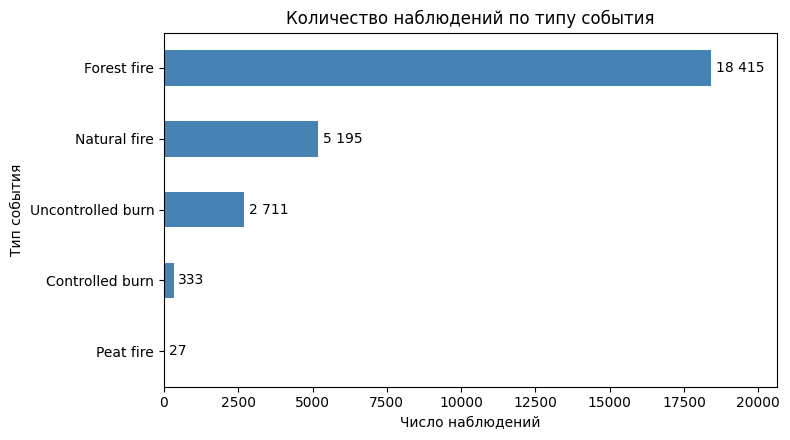

In [16]:
counts = df["type_name"].value_counts().sort_values()
ax = counts.plot(kind="barh", figsize=(8, 4.5), color="steelblue")
ax.set_title("Количество наблюдений по типу события")
ax.set_xlabel("Число наблюдений")
ax.set_ylabel("Тип события")
for i, v in enumerate(counts.values):
    ax.text(v + 150, i, f"{v:,}".replace(",", " "), va="center")
ax.set_xlim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

**Вывод.** Диаграмма подтверждает сильный дисбаланс: `Forest fire` доминирует, `Peat fire` почти не виден.
При построении моделей метрика accuracy будет вводить в заблуждение — доминирующий класс сам по себе даёт ~69 % «верных» ответов.

### Практический блок 9.2. Histogram: распределение температуры

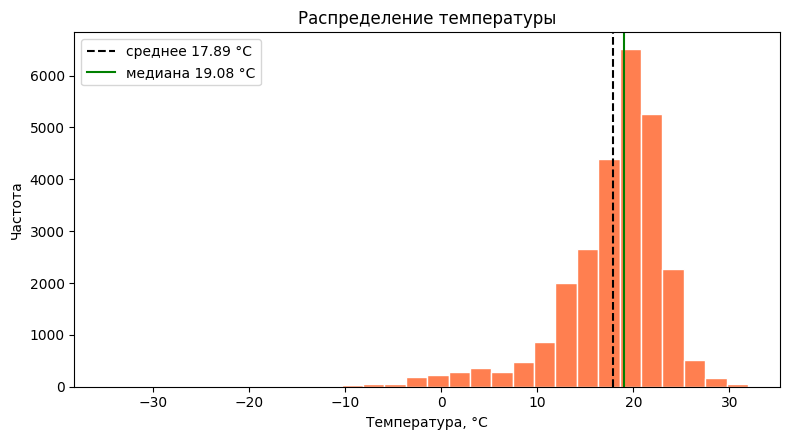

In [17]:
plt.figure(figsize=(8, 4.5))
plt.hist(df["temperature_c"], bins=30, edgecolor="white", color="coral")
plt.axvline(df["temperature_c"].mean(), color="black", linestyle="--",
            label=f"среднее {df['temperature_c'].mean():.2f} °C")
plt.axvline(df["temperature_c"].median(), color="green", linestyle="-",
            label=f"медиана {df['temperature_c'].median():.2f} °C")
plt.title("Распределение температуры")
plt.xlabel("Температура, °C")
plt.ylabel("Частота")
plt.legend()
plt.tight_layout()
plt.show()

**Вывод.** Основная масса наблюдений сосредоточена в диапазоне примерно 12–25 °C, распределение имеет длинный
левый хвост с отрицательными значениями до −34,88 °C; среднее лежит левее медианы. Считать холодные значения
ошибками по одному графику нельзя — это могут быть весенние/осенние палы и контролируемые выжигания.

### Практический блок 9.3. Scatter plot: температура и влажность

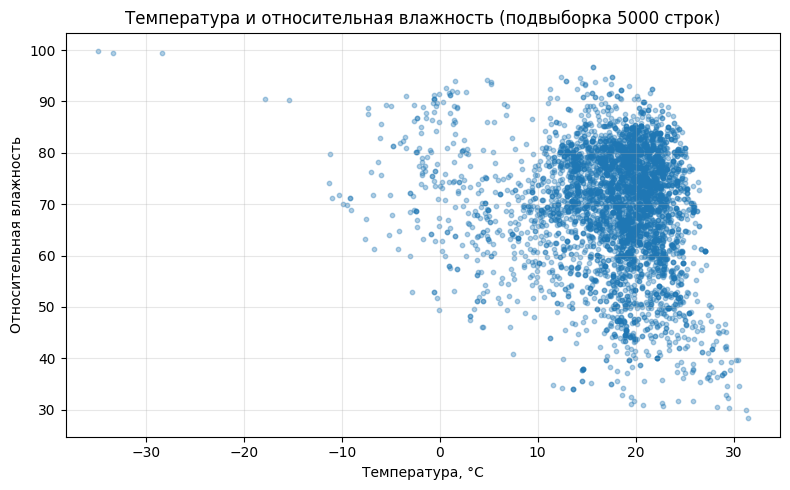

r (весь набор): -0.155


In [18]:
sample = df.sample(n=5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["temperature_c"], sample["relative_humidity"], s=10, alpha=0.35)
plt.title("Температура и относительная влажность (подвыборка 5000 строк)")
plt.xlabel("Температура, °C")
plt.ylabel("Относительная влажность")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("r (весь набор):", round(df["temperature_c"].corr(df["relative_humidity"]), 3))

**Вывод.** Точки образуют широкое облако без выраженной линии, что согласуется с r ≈ −0,155: с ростом температуры
влажность в среднем слегка снижается, но разброс очень велик. Фиксированный `random_state=42` делает подвыборку воспроизводимой.

### Практический блок 9.4. Пространственный scatter plot

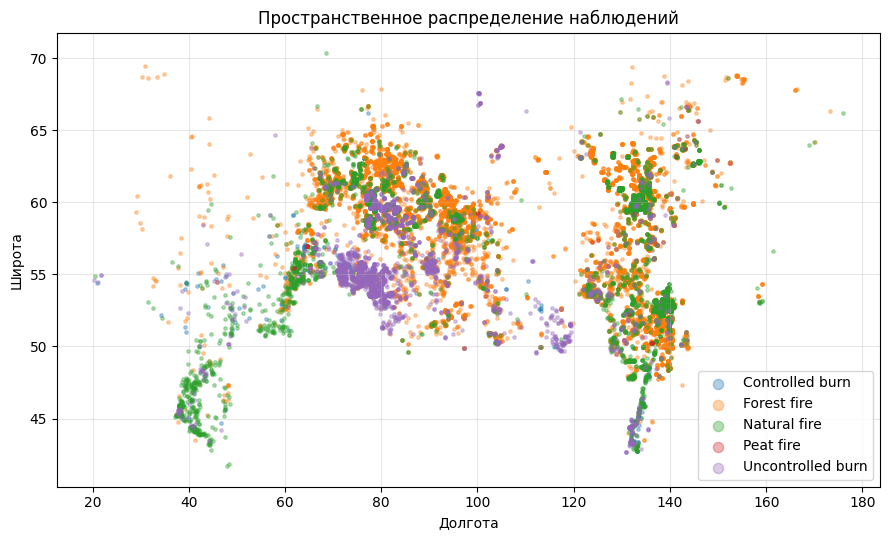

In [19]:
plt.figure(figsize=(9, 5.5))
for name, part in df.groupby("type_name"):
    plt.scatter(part["lon"], part["lat"], s=6, alpha=0.35, label=name)
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.title("Пространственное распределение наблюдений")
plt.legend(markerscale=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод.** Наблюдения покрывают долготы от ~20° до ~176° и широты от ~42° до ~70°, образуя несколько плотных
кластеров: Урал и Западная Сибирь (60–100° в. д.), Дальний Восток (125–145° в. д.) и юг европейской части (~40–48° в. д.).
Типы событий распределены неравномерно: `Uncontrolled burn` сконцентрирован в полосе около 52–57° с. ш. и 70–90° в. д.
(степные и сельскохозяйственные районы юга Западной Сибири), а `Forest fire` преобладает севернее и на Дальнем Востоке. Это разведочная диаграмма в декартовых осях, а не карта:
для географической интерпретации нужны проекция и границы регионов.

## 10. Экспорт CSV, JSON и Parquet
### Практический блок 10.1. Сохранение подготовленного DataFrame

In [20]:
OUT = Path("output")
OUT.mkdir(exist_ok=True)

clean_df.to_csv(OUT / "FiresRu_clean.csv", index=False, encoding="utf-8")
clean_df.to_json(OUT / "FiresRu_clean.json", orient="records", lines=True, force_ascii=False)
clean_df.to_parquet(OUT / "FiresRu_clean.parquet", index=False, engine="pyarrow", compression="snappy")

files = [OUT / "FiresRu_clean.csv", OUT / "FiresRu_clean.json", OUT / "FiresRu_clean.parquet"]
for path in files:
    size_mib = path.stat().st_size / 1024**2
    print(f"{path.name:24s} {size_mib:7.2f} MiB")

FiresRu_clean.csv           1.72 MiB
FiresRu_clean.json          5.81 MiB
FiresRu_clean.parquet       0.61 MiB


**Вывод.** Одна и та же таблица (11 столбцов, с вычисляемыми признаками) сохранена в трёх форматах.
JSON Lines — самый объёмный из-за повторения имён ключей в каждой строке, CSV — промежуточный,
Parquet — самый компактный благодаря колоночному хранению и сжатию snappy.

### Практический блок 10.2. Проверка round-trip

In [21]:
csv_back = pd.read_csv(OUT / "FiresRu_clean.csv")
parquet_back = pd.read_parquet(OUT / "FiresRu_clean.parquet")
json_back = pd.read_json(OUT / "FiresRu_clean.json", lines=True)

print("clean_df:", clean_df.shape)
print("CSV:     ", csv_back.shape)
print("JSON:    ", json_back.shape)
print("Parquet: ", parquet_back.shape)

dtypes_cmp = pd.DataFrame({
    "clean_df": clean_df.dtypes.astype(str),
    "CSV": csv_back.dtypes.astype(str),
    "Parquet": parquet_back.dtypes.astype(str),
})
print()
print(dtypes_cmp)
print("\nParquet полностью совпадает с исходным:", parquet_back.equals(clean_df))

clean_df: (26681, 11)
CSV:      (26681, 11)
JSON:     (26681, 11)
Parquet:  (26681, 11)

                   clean_df      CSV   Parquet
type_name          category   object  category
type_id                int8    int64      int8
lon                 float64  float64   float64
lat                 float64  float64   float64
temperature_c       float64  float64   float64
precipitation_mm    float64  float64   float64
relative_humidity   float64  float64   float64
wind_speed_ms       float64  float64   float64
solar_radiation     float64  float64   float64
wind_speed_kmh      float64  float64   float64
is_forest_fire         bool     bool      bool

Parquet полностью совпадает с исходным: True


**Вывод.** Число строк и столбцов совпадает во всех форматах. Parquet сохранил схему (`category`, `int8`, `bool`) и
восстанавливает таблицу без изменений; CSV вывел типы заново из текста — `type_name` вернулся строкой, `type_id` — `int64`.
Поэтому для аналитического pipeline (и далее для Spark) предпочтителен Parquet.

## 11. Итоговые выводы по набору FiresRu.csv

1. Таблица содержит 26 681 строку и 9 исходных признаков; пропусков и полных дубликатов нет.
2. Представлено пять типов событий; `Forest fire` занимает 69,02 % строк, `Peat fire` — 27 наблюдений (0,10 %). Набор сильно несбалансирован.
3. `type_id` — категориальный код, несмотря на целочисленный dtype; его среднее не имеет смысла.
4. Перевод `type_name` в `category` и `type_id` в `int8` уменьшает объём таблицы в памяти без потери информации (с 3,18 до 1,48 MiB, ≈53,5 % в pandas 2.x; ≈31 % в pandas 3, где строки изначально компактнее).
5. Температура лежит в диапазоне от −34,88 до 31,94 °C (медиана 19,08 °C) с длинным левым хвостом; осадки и ветер сильно скошены вправо.
6. Линейные корреляции между метеопризнаками слабые: максимальные по модулю ≈ 0,30 (температура–ветер, влажность–ветер).
7. Правило 1,5·IQR помечает 13,69 % значений скорости ветра — механическое удаление недопустимо.
8. Parquet — самый компактный формат и единственный из трёх, полностью сохраняющий схему.

**Ограничения:** в файле нет временного признака — сезонность и динамику изучить нельзя; координаты отображены в
декартовых осях, корректная картографическая интерпретация требует GIS-инструментов; единицы `relative_humidity`
и `solar_radiation` в метаданных не указаны.

# Часть II. Самостоятельная работа: анализ собственного датасета

## 1. Постановка задачи

**Датасет:** `taxis.csv` — поездки такси Нью-Йорка (жёлтые и зелёные такси) за март 2019 года.

**Источник:** NYC Taxi & Limousine Commission (TLC) Trip Record Data,
https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page. Использована подготовленная выборка из репозитория
seaborn-data: https://github.com/mwaskom/seaborn-data/blob/master/taxis.csv. Данные TLC публикуются как открытые
данные города Нью-Йорка (NYC Open Data, свободное использование). Персональных данных набор не содержит.

**Цель анализа:** оценить качество данных, описать структуру поездок (дальность, стоимость, чаевые, способ оплаты,
районы), выявить аномальные записи и посмотреть динамику числа поездок во времени.

## 2. Загрузка и паспорт данных

Перед чтением явно проверим кодировку и разделитель: посмотрим первые байты файла и попробуем декодировать их как UTF-8.

In [22]:
TAXI_PATH = Path("own_data/taxis.csv")
if not TAXI_PATH.exists():  # в Google Colab файл загружен в корень сессии
    TAXI_PATH = Path("taxis.csv")

raw = TAXI_PATH.read_bytes()
print("Размер файла:", round(len(raw) / 1024, 1), "KiB")
print("BOM UTF-8:", raw.startswith(b"\xef\xbb\xbf"))
raw.decode("utf-8")  # не выбросило ошибку -> файл корректно читается как UTF-8
first_line = raw.split(b"\n")[0].decode("utf-8")
print("Первая строка:", first_line)
print("Запятых:", first_line.count(","), "| точек с запятой:", first_line.count(";"), "| табуляций:", first_line.count("\t"))

Размер файла: 849.0 KiB
BOM UTF-8: False
Первая строка: pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
Запятых: 13 | точек с запятой: 0 | табуляций: 0


Файл в UTF-8 без BOM, разделитель — запятая (13 запятых → 14 столбцов). Читаем с явными параметрами.

In [23]:
taxi = pd.read_csv(TAXI_PATH, sep=",", encoding="utf-8")
print(taxi.shape)
print(taxi.columns.tolist())
taxi.head()

(6433, 14)
['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


**Паспорт данных**

| Параметр | Значение |
|---|---|
| Источник | NYC TLC Trip Record Data (выборка seaborn-data) |
| Предметная область | городской транспорт, поездки такси |
| Период | март 2019 |
| Размер | 6 433 строки × 14 столбцов |

| Поле | Тип (по смыслу) | Описание |
|---|---|---|
| `pickup` | дата-время | момент посадки пассажира |
| `dropoff` | дата-время | момент высадки |
| `passengers` | целое (дискретное) | число пассажиров |
| `distance` | число | расстояние поездки, мили |
| `fare` | число | тариф по счётчику, USD |
| `tip` | число | чаевые, USD |
| `tolls` | число | платные дороги/мосты, USD |
| `total` | число | итоговая сумма, USD (включает также налоги и сборы, которых нет в таблице) |
| `color` | категория | `yellow` / `green` — тип такси |
| `payment` | категория | способ оплаты: `credit card` / `cash` |
| `pickup_zone`, `dropoff_zone` | категория | зона посадки / высадки TLC |
| `pickup_borough`, `dropoff_borough` | категория | округ посадки / высадки |

## 3. Качество и предобработка
### 3.1. head / info / describe

In [24]:
buf = io.StringIO()
taxi.info(buf=buf, memory_usage="deep")
print(buf.getvalue())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 3.3 MB



**Вывод.** `pickup` и `dropoff` прочитаны как строки, а не даты — CSV не хранит схему, их нужно явно привести к `datetime`.
В столбцах `payment`, зонах и округах есть пропуски (non-null меньше 6 433).

In [25]:
taxi.describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pickup,6433,6414,2019-03-13 10:57:06,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dropoff,6433,6425,2019-03-04 18:08:13,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
passengers,6433.0,NaN,NaN,NaN,1.539251,1.203768,0.0,1.0,1.0,2.0,6.0
distance,6433.0,NaN,NaN,NaN,3.024617,3.827867,0.0,0.98,1.64,3.21,36.7
fare,6433.0,NaN,NaN,NaN,13.091073,11.551804,1.0,6.5,9.5,15.0,150.0
tip,6433.0,NaN,NaN,NaN,1.97922,2.44856,0.0,0.0,1.7,2.8,33.2
tolls,6433.0,NaN,NaN,NaN,0.325273,1.415267,0.0,0.0,0.0,0.0,24.02
total,6433.0,NaN,NaN,NaN,18.517794,13.81557,1.3,10.8,14.16,20.3,174.82
color,6433,2,yellow,5451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment,6389,2,credit card,4577,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Вывод.** Средняя поездка — около 3 миль и 13 USD по счётчику; медианы ниже средних, т. е. распределения
расстояния и стоимости скошены вправо. Есть подозрительные значения: `distance` и `passengers` с минимумом 0 и
длинные хвосты по `fare`/`total`. Среди категорий лидируют жёлтые такси, оплата картой и Манхэттен.

### 3.2. Пропуски, дубликаты, уникальные значения

In [26]:
missing = pd.DataFrame({
    "missing": taxi.isna().sum(),
    "missing_pct": (taxi.isna().mean() * 100).round(2),
    "nunique": taxi.nunique(),
})
print(missing)
print("\nПолных дубликатов:", taxi.duplicated().sum())

                 missing  missing_pct  nunique
pickup                 0         0.00     6414
dropoff                0         0.00     6425
passengers             0         0.00        7
distance               0         0.00     1079
fare                   0         0.00      220
tip                    0         0.00      489
tolls                  0         0.00       16
total                  0         0.00      898
color                  0         0.00        2
payment               44         0.68        2
pickup_zone           26         0.40      194
dropoff_zone          45         0.70      203
pickup_borough        26         0.40        4
dropoff_borough       45         0.70        5

Полных дубликатов: 0


In [27]:
# Пересекаются ли пропуски зоны и округа? (если да - это одна и та же неизвестная локация)
print("pickup_zone NaN, а pickup_borough заполнен:",
      (taxi["pickup_zone"].isna() & taxi["pickup_borough"].notna()).sum())
print("dropoff_zone NaN, а dropoff_borough заполнен:",
      (taxi["dropoff_zone"].isna() & taxi["dropoff_borough"].notna()).sum())
print("\nСтроки с пропуском payment:")
print(taxi.loc[taxi["payment"].isna(), ["fare", "tip", "total"]].describe().round(2))

pickup_zone NaN, а pickup_borough заполнен: 0
dropoff_zone NaN, а dropoff_borough заполнен: 0

Строки с пропуском payment:
        fare   tip  total
count  44.00  44.0  44.00
mean   11.99   0.0  15.10
std    13.54   0.0  14.57
min     2.50   0.0   3.80
25%     3.88   0.0   6.18
50%     8.50   0.0  11.80
75%    14.12   0.0  16.55
max    72.00   0.0  72.00


**Вывод и решения по пропускам.**
- Полных дубликатов нет — удалять нечего.
- `payment` пропущен в 44 строках (0,68 %). Тип оплаты нельзя восстановить надёжно, но и удалять поездки
  (их стоимость и маршрут корректны) нет причины → заполняем категорией `unknown`.
- Пропуски зон и округов (≤ 0,7 %) совпадают попарно: если неизвестна зона, неизвестен и округ — это поездки с
  неопределённой локацией (вероятно, за пределами зон TLC). Заполняем `Unknown`, строки сохраняем.
- Количественные поля пропусков не содержат.

### 3.3. Приведение типов и оптимизация памяти

In [28]:
mem_before = taxi.memory_usage(deep=True).sum()

taxi_clean = taxi.copy()

# даты: строка -> datetime
taxi_clean["pickup"] = pd.to_datetime(taxi_clean["pickup"], format="%Y-%m-%d %H:%M:%S")
taxi_clean["dropoff"] = pd.to_datetime(taxi_clean["dropoff"], format="%Y-%m-%d %H:%M:%S")

# пропуски в категориях
taxi_clean["payment"] = taxi_clean["payment"].fillna("unknown")
loc_cols = ["pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]
taxi_clean[loc_cols] = taxi_clean[loc_cols].fillna("Unknown")

# категории и компактные целые
cat_cols = ["color", "payment"] + loc_cols
taxi_clean[cat_cols] = taxi_clean[cat_cols].astype("category")
taxi_clean["passengers"] = taxi_clean["passengers"].astype("int8")

mem_after = taxi_clean.memory_usage(deep=True).sum()
print(f"До:       {mem_before / 1024**2:.2f} MiB")
print(f"После:    {mem_after / 1024**2:.2f} MiB")
print(f"Снижение: {(1 - mem_after / mem_before) * 100:.1f}%")
print("\nПропусков после обработки:", taxi_clean.isna().sum().sum())
print(taxi_clean.dtypes)

До:       3.32 MiB
После:    0.44 MiB
Снижение: 86.9%

Пропусков после обработки: 0
pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                   int8
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                    category
payment                  category
pickup_zone              category
dropoff_zone             category
pickup_borough           category
dropoff_borough          category
dtype: object


**Вывод.** Даты приведены к `datetime64` (теперь доступны арифметика времени и временная агрегация), шесть текстовых
столбцов с небольшим числом повторяющихся значений переведены в `category`, `passengers` — в `int8`. Объём в памяти
сократился в несколько раз; пропусков после обработки не осталось.

### 3.4. Вычисляемые признаки

- `duration_min = (dropoff − pickup) / 60 с` — длительность поездки, мин;
- `tip_pct = tip / fare · 100` — чаевые в % от тарифа (только при `fare > 0`);
- `speed_mph = distance / (duration_min / 60)` — средняя скорость, миль/ч (только при длительности > 0);
- `pickup_hour`, `pickup_date` — час и дата посадки для временной агрегации;
- `is_airport` — логический признак: посадка или высадка в аэропорту (зона содержит «Airport»).

In [29]:
taxi_clean["duration_min"] = (
    (taxi_clean["dropoff"] - taxi_clean["pickup"]).dt.total_seconds() / 60
).round(2)
taxi_clean["tip_pct"] = (taxi_clean["tip"] / taxi_clean["fare"].where(taxi_clean["fare"] > 0) * 100).round(2)
taxi_clean["speed_mph"] = (
    taxi_clean["distance"] / (taxi_clean["duration_min"].where(taxi_clean["duration_min"] > 0) / 60)
).round(2)
taxi_clean["pickup_hour"] = taxi_clean["pickup"].dt.hour.astype("int8")
taxi_clean["pickup_date"] = taxi_clean["pickup"].dt.normalize()
taxi_clean["is_airport"] = (
    taxi_clean["pickup_zone"].astype(str).str.contains("Airport")
    | taxi_clean["dropoff_zone"].astype(str).str.contains("Airport")
)

print(taxi_clean[["pickup", "dropoff", "duration_min", "distance", "speed_mph",
                  "fare", "tip", "tip_pct", "is_airport"]].head())
print("\nПоездок через аэропорт:", taxi_clean["is_airport"].sum())

               pickup             dropoff  duration_min  distance  speed_mph  fare   tip  tip_pct  is_airport
0 2019-03-23 20:21:09 2019-03-23 20:27:24          6.25      1.60      15.36   7.0  2.15    30.71       False
1 2019-03-04 16:11:55 2019-03-04 16:19:00          7.08      0.79       6.69   5.0  0.00     0.00       False
2 2019-03-27 17:53:01 2019-03-27 18:00:25          7.40      1.37      11.11   7.5  2.36    31.47       False
3 2019-03-10 01:23:59 2019-03-10 01:49:51         25.87      7.70      17.86  27.0  6.15    22.78       False
4 2019-03-30 13:27:42 2019-03-30 13:37:14          9.53      2.16      13.60   9.0  1.10    12.22       False

Поездок через аэропорт: 407


**Вывод.** Признаки рассчитаны векторно. `duration_min` и `speed_mph` нужны и для анализа, и для проверки
правдоподобия записей (см. следующий блок); `tip_pct` позволяет сравнивать чаевые независимо от длины поездки.

### 3.5. Семантическая проверка правдоподобия записей

In [30]:
checks = {
    "distance == 0":               (taxi_clean["distance"] == 0),
    "passengers == 0":             (taxi_clean["passengers"] == 0),
    "duration <= 0 мин":           (taxi_clean["duration_min"] <= 0),
    "duration > 180 мин":          (taxi_clean["duration_min"] > 180),
    "speed > 70 миль/ч":           (taxi_clean["speed_mph"] > 70),
    "total < fare + tip + tolls":  (taxi_clean["total"] + 0.01 < taxi_clean[["fare", "tip", "tolls"]].sum(axis=1)),
    "чаевые при оплате наличными": ((taxi_clean["payment"] == "cash") & (taxi_clean["tip"] > 0)),
}
quality = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="строк")
print(quality)

taxi_clean["is_suspicious"] = (
    checks["distance == 0"] | checks["duration <= 0 мин"]
    | checks["duration > 180 мин"] | checks["speed > 70 миль/ч"]
)
print("\nПомечено подозрительными (флаг is_suspicious):", taxi_clean["is_suspicious"].sum(),
      f"({taxi_clean['is_suspicious'].mean() * 100:.2f}%)")

distance == 0                  51
passengers == 0                96
duration <= 0 мин               6
duration > 180 мин              0
speed > 70 миль/ч              11
total < fare + tip + tolls      0
чаевые при оплате наличными     0
Name: строк, dtype: int64

Помечено подозрительными (флаг is_suspicious): 62 (0.96%)


**Вывод.** Отсутствие пропусков и дубликатов не гарантирует качества: найдены поездки с нулевым расстоянием,
нулевым числом пассажиров и нереалистичной длительностью/скоростью. Строки **не удаляются**, а помечаются флагом
`is_suspicious` — без описания процедуры сбора данных TLC нельзя утверждать, что это ошибки (например, отменённая
поездка с минимальным тарифом). Чаевые при оплате наличными в данных равны нулю во всех строках: водитель не вносит их в
счётчик, поэтому анализ чаевых корректен только для оплаты картой.

## 4. EDA
### 4.1. Составной фильтр (loc / query)

Длинные поездки (более 10 миль), оплаченные картой, без признаков аномалий.

In [31]:
long_card = taxi_clean.query("distance > 10 and payment == 'credit card' and not is_suspicious")
print("Строк:", len(long_card), f"({len(long_card) / len(taxi_clean) * 100:.2f}%)")
print("Из них через аэропорт:", long_card["is_airport"].sum())
print(long_card[["pickup_zone", "dropoff_zone", "distance", "fare", "tip_pct"]].head())

# то же через loc: поздние поездки (0-5 ч) в Манхэттене
night_mn = taxi_clean.loc[
    (taxi_clean["pickup_hour"] < 5) & (taxi_clean["pickup_borough"] == "Manhattan"),
    ["pickup", "pickup_zone", "distance", "fare"]
]
print("\nНочных поездок с посадкой в Манхэттене:", len(night_mn))

Строк: 325 (5.05%)
Из них через аэропорт: 192
                   pickup_zone           dropoff_zone  distance   fare  tip_pct
56                 JFK Airport  Upper East Side North     19.59  52.00     0.00
92                East Tremont           Midtown East     10.60  33.50     0.00
111  Times Sq/Theatre District      LaGuardia Airport     11.93  39.50    24.58
127               East Chelsea            Marble Hill     10.21  37.61     0.00
128          LaGuardia Airport           Clinton East     10.80  36.00    31.94

Ночных поездок с посадкой в Манхэттене: 424


**Вывод.** Длинных (> 10 миль) поездок, оплаченных картой, — 325 (5 % выборки), и 192 из них (59 %) связаны
с аэропортами (JFK, LaGuardia) — именно аэропорты формируют «хвост» распределения расстояний и стоимости.
Ночных (0–5 ч) посадок в Манхэттене — 424, т. е. около 8 % манхэттенских поездок.

### 4.2. Группировки и агрегирование

In [32]:
by_payment = (
    taxi_clean.groupby("payment", observed=True)
    .agg(
        n=("fare", "size"),
        fare_mean=("fare", "mean"),
        fare_median=("fare", "median"),
        tip_mean=("tip", "mean"),
        tip_pct_median=("tip_pct", "median"),
        distance_mean=("distance", "mean"),
    )
    .sort_values("n", ascending=False)
)
print(by_payment.round(2))

                n  fare_mean  fare_median  tip_mean  tip_pct_median  distance_mean
payment                                                                           
credit card  4577      13.69          9.5      2.78            25.5           3.22
cash         1812      11.59          8.5      0.00             0.0           2.54
unknown        44      11.99          8.5      0.00             0.0           2.43


**Вывод.** При оплате картой медианные чаевые составляют ≈25,5 % тарифа, при оплате наличными и с неизвестным
способом оплаты — 0 (не фиксируются). Поездки по карте в среднем немного длиннее (3,2 против 2,5 мили), но эта
разница несопоставима с разницей в чаевых: она объясняется способом учёта, а не типом поездок. Группа `unknown`
мала (44 строки), выводы по ней ненадёжны.

In [33]:
by_borough = (
    taxi_clean.groupby("pickup_borough", observed=True)
    .agg(
        n=("fare", "size"),
        share_pct=("fare", lambda s: len(s) / len(taxi_clean) * 100),
        distance_median=("distance", "median"),
        fare_mean=("fare", "mean"),
        fare_max=("fare", "max"),
        duration_median=("duration_min", "median"),
    )
    .sort_values("n", ascending=False)
)
print(by_borough.round(2))

                   n  share_pct  distance_median  fare_mean  fare_max  duration_median
pickup_borough                                                                        
Manhattan       5268      81.89              1.5      11.15    130.00            10.23
Queens           657      10.21              6.1      24.93    150.00            18.72
Brooklyn         383       5.95              2.6      16.52     93.50            14.27
Bronx             99       1.54              4.0      21.00     81.86            20.63
Unknown           26       0.40              0.4      25.88    120.00             1.65


In [34]:
# сводная таблица: доля жёлтых/зелёных такси по округу посадки
print(pd.crosstab(taxi_clean["pickup_borough"], taxi_clean["color"], normalize="index").mul(100).round(1))

color           green  yellow
pickup_borough               
Bronx            83.8    16.2
Brooklyn         81.7    18.3
Manhattan         5.6    94.4
Queens           43.8    56.2
Unknown          15.4    84.6


**Вывод.** 81,9 % поездок начинается в Манхэттене, и это короткие поездки (медиана 1,5 мили, ~10 минут).
Из Квинса (где находятся аэропорты JFK и LaGuardia) поездки в 4 раза длиннее и в 2 раза дороже. В Манхэттене 94 %
посадок приходится на жёлтые такси, в Бруклине и Бронксе более 80 % — на зелёные; это соответствует правилам TLC
(зелёные такси не берут пассажиров в центральном Манхэттене). Квинс смешанный (56 % жёлтых) — за счёт аэропортов,
где жёлтые такси работают с выделенных стоянок.

### 4.3. Описательная статистика, корреляция и выбросы

In [35]:
num_cols = ["distance", "fare", "tip", "tolls", "total", "duration_min", "passengers"]
print(taxi_clean[num_cols].describe().round(2).T)

               count   mean    std  min    25%    50%    75%     max
distance      6433.0   3.02   3.83  0.0   0.98   1.64   3.21   36.70
fare          6433.0  13.09  11.55  1.0   6.50   9.50  15.00  150.00
tip           6433.0   1.98   2.45  0.0   0.00   1.70   2.80   33.20
tolls         6433.0   0.33   1.42  0.0   0.00   0.00   0.00   24.02
total         6433.0  18.52  13.82  1.3  10.80  14.16  20.30  174.82
duration_min  6433.0  14.35  11.64  0.0   6.50  10.90  18.52  107.67
passengers    6433.0   1.54   1.20  0.0   1.00   1.00   2.00    6.00


In [36]:
corr_t = taxi_clean.loc[~taxi_clean["is_suspicious"], ["distance", "fare", "tip", "tolls", "total", "duration_min"]].corr()
print(corr_t.round(3))

              distance   fare    tip  tolls  total  duration_min
distance         1.000  0.959  0.474  0.646  0.943         0.824
fare             0.959  1.000  0.468  0.617  0.974         0.887
tip              0.474  0.468  1.000  0.410  0.631         0.410
tolls            0.646  0.617  0.410  1.000  0.691         0.470
total            0.943  0.974  0.631  0.691  1.000         0.856
duration_min     0.824  0.887  0.410  0.470  0.856         1.000


**Вывод.** Расстояние, тариф и итоговая сумма связаны очень сильно (r > 0,9) — тариф по счётчику в основном
определяется расстоянием, а `total` включает `fare`. Длительность связана с тарифом слабее: в пробках время
растёт, а расстояние — нет. Корреляция чаевых с тарифом умеренная, поскольку при оплате наличными чаевые равны 0.

In [37]:
q1, q3 = taxi_clean["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
fare_out = (taxi_clean["fare"] < lower) | (taxi_clean["fare"] > upper)

print(f"Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}")
print(f"Границы: [{lower:.2f}; {upper:.2f}]")
print(f"Кандидатов: {fare_out.sum()} ({fare_out.mean() * 100:.2f}%)")
print("Из них связаны с аэропортом:", f"{taxi_clean.loc[fare_out, 'is_airport'].mean() * 100:.1f}%")

Q1=6.50; Q3=15.00; IQR=8.50
Границы: [-6.25; 27.75]
Кандидатов: 592 (9.20%)
Из них связаны с аэропортом: 53.0%


**Вывод.** Правило 1,5·IQR помечает 592 поездки (9,2 %) с тарифом выше 27,75 USD, причём 53 % из них — поездки
через аэропорт (а в целом по набору аэропортовых поездок только ~6 %). Это реальные дорогие поездки, а не ошибки, поэтому они сохраняются в данных.

### 4.4. Визуализации
#### Рис. 1. Категориальное сравнение: поездки по округу посадки и типу такси

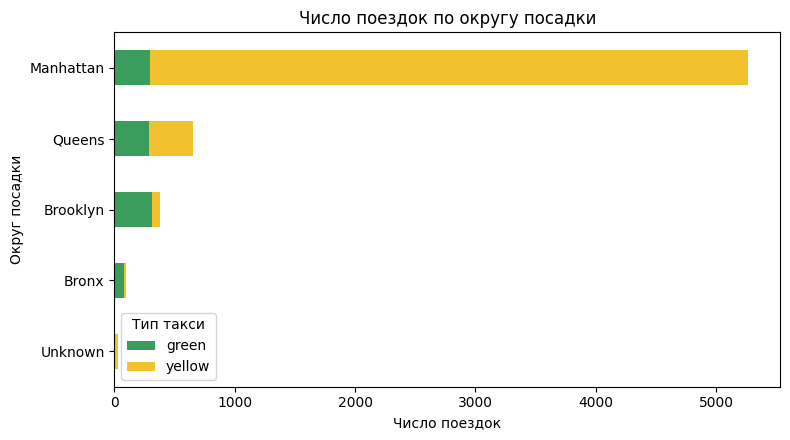

In [38]:
ct = pd.crosstab(taxi_clean["pickup_borough"], taxi_clean["color"])
ct = ct.loc[ct.sum(axis=1).sort_values().index]
ax = ct.plot(kind="barh", stacked=True, figsize=(8, 4.5), color={"yellow": "#f2c12e", "green": "#3a9d5d"})
ax.set_title("Число поездок по округу посадки")
ax.set_xlabel("Число поездок")
ax.set_ylabel("Округ посадки")
ax.legend(title="Тип такси")
plt.tight_layout()
plt.show()

**Вывод.** Манхэттен доминирует и обслуживается почти полностью жёлтыми такси; в остальных округах значимая доля
у зелёных такси. Набор несбалансирован по географии: выводы по Бронксу и Стейтен-Айленду основаны на малом числе поездок.

#### Рис. 2. Распределение: стоимость поездки

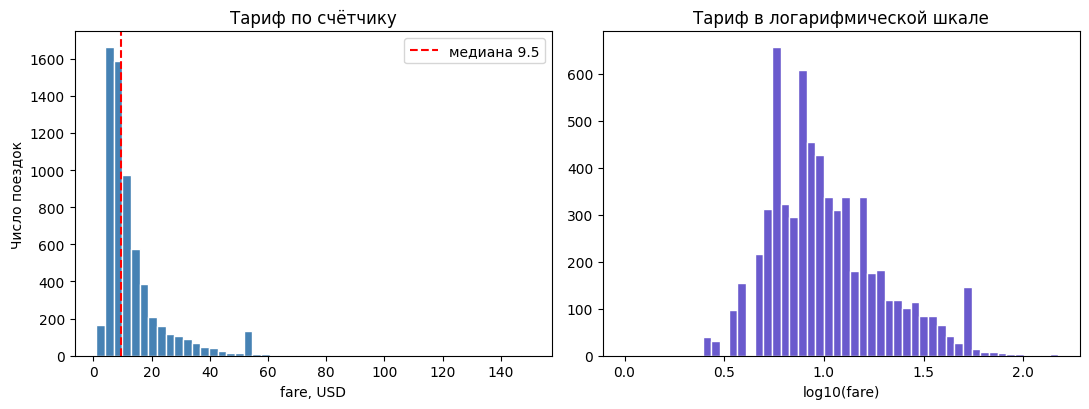

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(taxi_clean["fare"], bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(taxi_clean["fare"].median(), color="red", linestyle="--",
                label=f"медиана {taxi_clean['fare'].median():.1f}")
axes[0].set_title("Тариф по счётчику")
axes[0].set_xlabel("fare, USD")
axes[0].set_ylabel("Число поездок")
axes[0].legend()

axes[1].hist(np.log10(taxi_clean.loc[taxi_clean["fare"] > 0, "fare"]), bins=50, color="slateblue", edgecolor="white")
axes[1].set_title("Тариф в логарифмической шкале")
axes[1].set_xlabel("log10(fare)")
plt.tight_layout()
plt.show()

**Вывод.** Распределение тарифа сильно скошено вправо: большинство поездок стоят 5–15 USD, а хвост тянется до
сотни и более. В логарифмической шкале видна основная мода и отдельный «горб» в районе ~52 USD — фиксированный
тариф JFK ↔ Манхэттен.

#### Рис. 3. Взаимосвязь: расстояние и стоимость

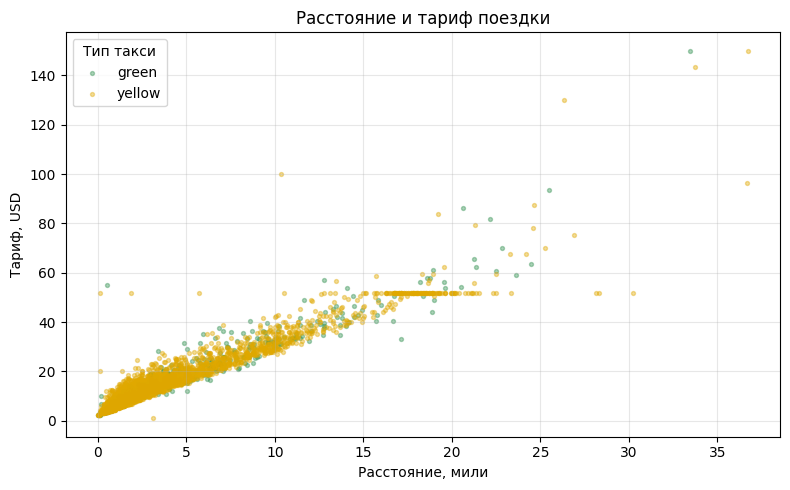

In [40]:
ok = taxi_clean.loc[~taxi_clean["is_suspicious"]]
plt.figure(figsize=(8, 5))
for name, part in ok.groupby("color", observed=True):
    plt.scatter(part["distance"], part["fare"], s=8, alpha=0.4, label=name,
                color={"yellow": "#e0a800", "green": "#2f8f4e"}[name])
plt.title("Расстояние и тариф поездки")
plt.xlabel("Расстояние, мили")
plt.ylabel("Тариф, USD")
plt.legend(title="Тип такси")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод.** Точки ложатся вдоль почти прямой линии (≈2,5 USD за милю + посадка), что подтверждает сильную
корреляцию. Отчётливо видна горизонтальная «полка» около 52 USD — фиксированный тариф аэропорта JFK,
не зависящий от расстояния.

#### Рис. 4. Временной ряд: число поездок по дням (и по часам суток)

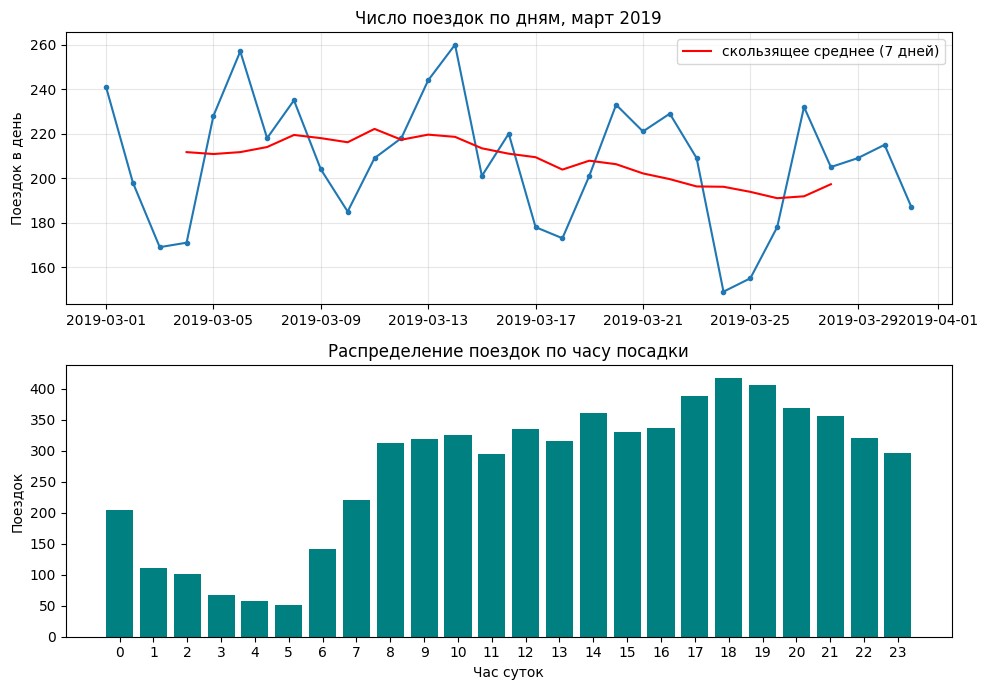

Записей вне марта 2019: 1


In [41]:
daily = taxi_clean.set_index("pickup").resample("D").size()
daily = daily.loc["2019-03"]

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(daily.index, daily.values, marker="o", markersize=3)
axes[0].plot(daily.index, daily.rolling(7, center=True).mean(), color="red", label="скользящее среднее (7 дней)")
axes[0].set_title("Число поездок по дням, март 2019")
axes[0].set_ylabel("Поездок в день")
axes[0].legend()
axes[0].grid(alpha=0.3)

hourly = taxi_clean.groupby("pickup_hour").size()
axes[1].bar(hourly.index, hourly.values, color="teal")
axes[1].set_title("Распределение поездок по часу посадки")
axes[1].set_xlabel("Час суток")
axes[1].set_ylabel("Поездок")
axes[1].set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

print("Записей вне марта 2019:", (taxi_clean["pickup"].dt.to_period("M") != "2019-03").sum())

**Вывод.** Набор содержит дату, поэтому построен настоящий временной ряд по `pickup` (а не по индексу строк).
Число поездок в день колеблется от ~150 до ~260 (в среднем ≈ 207) с небольшим снижением скользящего среднего к
концу месяца; одна запись относится к 1 апреля и в дневной ряд не вошла. Это случайная выборка из полного массива
TLC, так что абсолютные значения отражают объём выборки, а не реальный поток. По часам выражен суточный цикл:
минимум в 3–5 ч (около 50–70 поездок), рост с 7 ч и пик в 18–19 ч (≈ 400 поездок).

## 5. Экспорт

In [42]:
cols_out = [c for c in taxi_clean.columns if c != "pickup_date"]  # pickup_date дублирует pickup
taxi_out = taxi_clean[cols_out]

taxi_out.to_csv(OUT / "taxis_clean.csv", index=False, encoding="utf-8")
taxi_out.to_json(OUT / "taxis_clean.json", orient="records", lines=True, force_ascii=False, date_format="iso")
taxi_out.to_parquet(OUT / "taxis_clean.parquet", index=False, engine="pyarrow", compression="snappy")

for path in [OUT / "taxis_clean.csv", OUT / "taxis_clean.json", OUT / "taxis_clean.parquet"]:
    print(f"{path.name:22s} {path.stat().st_size / 1024:8.1f} KiB")

taxis_clean.csv          1042.2 KiB
taxis_clean.json         2677.4 KiB
taxis_clean.parquet       251.9 KiB


In [43]:
t_csv = pd.read_csv(OUT / "taxis_clean.csv")
t_pq = pd.read_parquet(OUT / "taxis_clean.parquet")
print("Исходный:", taxi_out.shape, "| CSV:", t_csv.shape, "| Parquet:", t_pq.shape)

cmp = pd.DataFrame({"исходный": taxi_out.dtypes.astype(str),
                    "CSV": t_csv.dtypes.astype(str),
                    "Parquet": t_pq.dtypes.astype(str)})
print(cmp)
print("\nParquet совпадает с исходным:", t_pq.equals(taxi_out))

Исходный: (6433, 20) | CSV: (6433, 20) | Parquet: (6433, 20)
                       исходный      CSV         Parquet
pickup           datetime64[ns]   object  datetime64[ns]
dropoff          datetime64[ns]   object  datetime64[ns]
passengers                 int8    int64            int8
distance                float64  float64         float64
fare                    float64  float64         float64
tip                     float64  float64         float64
tolls                   float64  float64         float64
total                   float64  float64         float64
color                  category   object        category
payment                category   object        category
pickup_zone            category   object        category
dropoff_zone           category   object        category
pickup_borough         category   object        category
dropoff_borough        category   object        category
duration_min            float64  float64         float64
tip_pct                 flo

**Вывод.** Размеры таблиц после повторного чтения совпадают. Parquet — самый компактный и восстанавливает
`datetime64`, `category`, `int8` и `bool` без потерь. Из CSV даты читаются как строки, а категории — как обычные строки,
поэтому после чтения CSV приведение типов пришлось бы повторять.

## 6. Итог по собственному датасету

**Выводы:**
1. Набор содержит 6 433 поездки и 14 исходных признаков за март 2019 г.; полных дубликатов нет, пропуски (< 1 %)
   есть только в категориальных полях (`payment`, зоны и округа) и заполнены явными категориями `unknown`/`Unknown`.
2. Отсутствие пропусков в числовых полях не означает их корректности: найдены поездки с нулевым расстоянием,
   нулевым числом пассажиров и нереалистичной длительностью/скоростью; они помечены флагом `is_suspicious`.
3. Приведение типов (`datetime64`, `category`, `int8`) уменьшило объём таблицы в памяти в несколько раз.
4. 82 % поездок начинается в Манхэттене (медиана 1,5 мили), 94 % из них — на жёлтых такси; зелёные такси
   работают в основном в Бруклине и Бронксе.
5. Тариф почти линейно зависит от расстояния (r ≈ 0,96); исключение — фиксированный тариф JFK ≈ 52 USD.
6. Распределение стоимости сильно скошено вправо; кандидаты в выбросы по правилу IQR — в основном реальные
   поездки в аэропорты, поэтому они не удаляются.
7. Чаевые фиксируются только при оплате картой (медиана ≈ 25,5 % тарифа); при оплате наличными они равны нулю.
8. Суточный профиль спроса выражен: минимум в 3–5 ч, пик в 18–19 ч.

**Ограничения анализа:**
1. Это выборка из полного массива TLC за один месяц — абсолютное число поездок и сезонность по ней оценить нельзя.
2. Чаевые наличными в данных не регистрируются, поэтому сравнение чаевых по способам оплаты отражает способ учёта, а не поведение пассажиров.
3. Состав `total` (налоги, сборы, доплаты) в таблице не раскрыт, поэтому `total` нельзя полностью проверить через другие поля.
4. Причины аномальных записей (нулевая дистанция, отрицательная длительность) без документации источника установить нельзя.

# Ответы на контрольные вопросы

**1. Почему dtype числового столбца не гарантирует, что признак является количественным?**
Числом может быть закодирована категория (`type_id`, почтовый индекс, номер района). dtype описывает способ хранения,
а не смысл; для кодов арифметика (среднее, сумма) не имеет смысла.

**2. Чем DataFrame отличается от NumPy ndarray с точки зрения схемы и типов?**
ndarray однороден — один dtype на весь массив, доступ по позициям. DataFrame — набор столбцов-Series, у каждого свой
dtype, есть именованные столбцы и индекс строк, т. е. у таблицы есть схема.

**3. Какие задачи решают head(), info() и describe()?**
`head()` — визуальная проверка, что таблица прочитана правильно; `info()` — схема: типы, число непустых значений,
память; `describe()` — числовые сводки (центр, разброс, квантили, диапазон). Каждая отвечает на свой вопрос,
поэтому одна не заменяет остальные.

**4. Почему отсутствие пропусков и дубликатов ещё не означает отсутствие проблем качества?**
Значения могут быть заполнены, но неправдоподобны: нули вместо пропусков, отрицательная длительность, неверные
единицы, неверно распознанные типы, рассогласование связанных полей (код ↔ название).

**5. В каких случаях category уменьшает память и почему?**
Когда уникальных значений мало относительно числа строк. Каждое уникальное значение хранится один раз,
а в строках — компактные целочисленные коды (int8/int16).

**6. Чем фильтрация отличается от группировки?**
Фильтрация отбирает подмножество строк по условию (результат — те же строки, их меньше). Группировка делит все
строки на группы и вычисляет агрегат для каждой (результат — одна строка на группу).

**7. Что означает коэффициент корреляции около нуля?**
Отсутствие выраженной **линейной** связи. Нельзя делать вывод, что зависимости нет вовсе (она может быть
нелинейной) или что признаки независимы; при этом и ненулевая корреляция не доказывает причинность.

**8. Почему правило IQR нельзя использовать как автоматический алгоритм удаления?**
Это эвристика для симметричных распределений. На скошенных данных оно помечает большую долю реальных наблюдений
(13,7 % в FiresRu, поездки в аэропорт в taxis). Решение об удалении требует предметной проверки.

**9. Как выбрать между histogram, bar chart, scatter plot и временным рядом?**
Bar chart — сравнение категорий; histogram — форма распределения одной числовой величины; scatter plot —
взаимосвязь двух числовых величин; временной ряд — значение, упорядоченное по реальному времени.

**10. Почему временной ряд нельзя строить по индексу строк?**
Порядок строк в файле не обязательно хронологический, а интервалы между строками неравномерны или неизвестны —
такой график создаёт ложную динамику.

**11. Какие преимущества Parquet даёт по сравнению с CSV?**
Хранит схему и типы, сжимается, позволяет читать только нужные столбцы, хранит статистики для пропуска блоков,
хорошо поддерживается Spark и другими распределёнными движками.

**12. Почему notebook должен корректно выполняться через Run All после перезапуска ядра?**
Только так гарантируется, что результат не зависит от скрытого состояния (удалённых ячеек, ручного порядка
запуска, старых переменных) и может быть воспроизведён другим человеком.